# Does any model *generate* the $\rho$ distribution? Single units only → `figure_ks_stats_good.pdf`

[`../figure_4/figure_ks_stats.ipynb`](../figure_4/figure_ks_stats.ipynb), over **well-isolated
single units only** instead of the whole population.

The question is not which model fits best but whether a model, taken as the truth, would
**produce the distribution of $\rho$ that was measured**. For every neuron and every
candidate model, spikes are simulated from that neuron's own fitted parameters, the
relational-bias model is refit to the synthetic trials, and the resulting $\rho$ values are
pooled into a synthetic distribution. The figure overlays each model's synthetic ECDF on the
real one; the widest vertical gap between them is that model's KS statistic.

The relational-bias curve is the **noise floor**, not a result: it is the model refit to data
simulated from itself, so it shows how much the estimator alone spreads $\rho$ out. Every
other model should be read against it.

**Nothing is re-simulated here.** The synthetic-alpha cache is keyed per (neuron, model,
replicate) with a fingerprint of the fitted parameters, so a single-unit subset reuses exactly
the rows already computed for the pooled figure — and `ks_lib.synthetic_biases` restricts what it
returns to this call's neurons. The run prints what it reused
and what it dropped.


In [1]:
import matplotlib.pyplot as plt
import numpy as np

import common
import fit_lib
import ks_lib
import relationality_lib as rl

common.set_style()

# The comparison this figure makes, in figure order — the same set and order as
# `../figure_4/figure_model_comparison.ipynb`, so the supplement and the main figure can be
# read against each other. 'constant' is the reference and is added automatically.
MODELS = (
    'weighted_average',
    'normalization',
    'inhibition',
    'basis_function',
    'future_field',
)

# The accents, identical to the main figure: the two leading models get a warm hue each and
# everything else is a light-to-dark grey ramp.
ACCENT, ACCENT_MODEL = '#c1272d', 'future_field'
SECOND_ACCENT, SECOND_ACCENT_MODEL = '#8e3b6b', 'basis_function'      # 'plum'
# This ramp is DARKER than figure_model_comparison.ipynb's 0.82/0.2, and is taken from
# `../figure_4/figure_ks_stats.ipynb` -- the figure this one is the single-unit version of.
# These are thin lines on a white panel, and the light end of that ramp does not read as a
# curve.
GRAY_LIGHT, GRAY_DARK = 0.78, 0.12


def model_colors(models=MODELS):
    """One colour per model in `models` order: accents by name, the rest a grey ramp."""
    accents = {ACCENT_MODEL: ACCENT, SECOND_ACCENT_MODEL: SECOND_ACCENT}
    n_grey = sum(m not in accents for m in models)
    greys = iter(np.linspace(GRAY_LIGHT, GRAY_DARK, max(n_grey, 1)))
    return [accents[m] if m in accents else str(next(greys)) for m in models]

CFG = fit_lib.FitConfig()      # the configuration the cache was built with

N_REPS = 5        # synthetic datasets per (neuron, model), all already on disk
SIM_SEED = 0
N_JOBS = 6        # joblib workers. Nothing should recompute — if it does, stop and check
                  #   the cache rather than letting it run.

FIGSIZE = (5.2, 2.9)
XLABEL = 'Relationality (r)'


## Colours and dashes

The two leading models carry a hue each; everything else is grey. Every model curve is dashed,
so it stays distinct from the solid data curve, and the dash lengths separate curves whose
colours are similar. The data curve is the one other colour.

In [2]:
DATA_COLOR = (0.13, 0.62, 0.31)
COLORS = dict(zip(MODELS, model_colors()))

# Dashes separate curves whose colours are close. The two accents are dashed so they stay
# distinct from the solid data curve, and the three greys get the three dash lengths in
# order, so the dash reads as a ramp alongside the grey ramp.
SHORT_DASH, MID_DASH, LONG_DASH = (0.0, (3, 3)), (0.0, (5.0, 3.0)), (0.0, (7.0, 3.0))
STYLES = {'future_field': LONG_DASH, 'basis_function': SHORT_DASH,
          'weighted_average': SHORT_DASH, 'normalization': MID_DASH,
          'inhibition': LONG_DASH}

## The figure

The KS table below carries the numbers the curves cannot: the statistic, its bootstrap CI, and
the p-value.


2-object modulation (Benjamini-Hochberg FDR q = 0.05, deviance explained >= 0.02): 1339 of 3011 neurons (44.5%)
  significance alone would keep 1801; the deviance floor drops a further 462
  modulation criterion: 1339 -> 1339 neurons
single units: 672 of 1339 neurons kept (50%)
  Elgar: 116
  Perle: 556
--- good: real bias median 0.701, 13.1% at 0, 0.1% at 1
33475 rows reused from cache, 0 computed
  dropped 667 cached neuron(s) that are not in this population
16800 synthetic neurons in 6s (cache/figures/figure_4/neuron_models/bias_recovery/8ee5ac260b62dffd)
16800 synthetic neurons


,subject,model,label,n,ks,ks_lo,ks_hi,p,median,frac_at_0,frac_at_1
0,Perle,future_field,Future Field,2780,0.040,0.032,0.068,0.455,0.704,0.106,0.002
1,Perle,basis_function,Basis Func.,2780,0.077,0.065,0.110,0.008,0.673,0.096,0.001
2,Perle,normalization,Normalization,2780,0.498,0.462,0.543,0.000,0.185,0.190,0.000
3,Perle,inhibition,Inhibition,2780,0.635,0.592,0.676,0.000,0.215,0.205,0.000
4,Perle,weighted_average,Weighted Avg.,2780,0.740,0.705,0.784,0.000,0.000,0.518,0.000
5,Elgar,future_field,Future Field,580,0.086,0.069,0.164,0.453,0.536,0.138,0.002
6,Elgar,basis_function,Basis Func.,580,0.121,0.095,0.207,0.113,0.499,0.138,0.002
7,Elgar,normalization,Normalization,580,0.467,0.396,0.569,0.000,0.112,0.255,0.000
8,Elgar,inhibition,Inhibition,580,0.567,0.474,0.672,0.000,0.177,0.212,0.000
9,Elgar,weighted_average,Weighted Avg.,580,0.688,0.595,0.785,0.000,0.000,0.521,0.000


saved figure_ks_stats_good.pdf


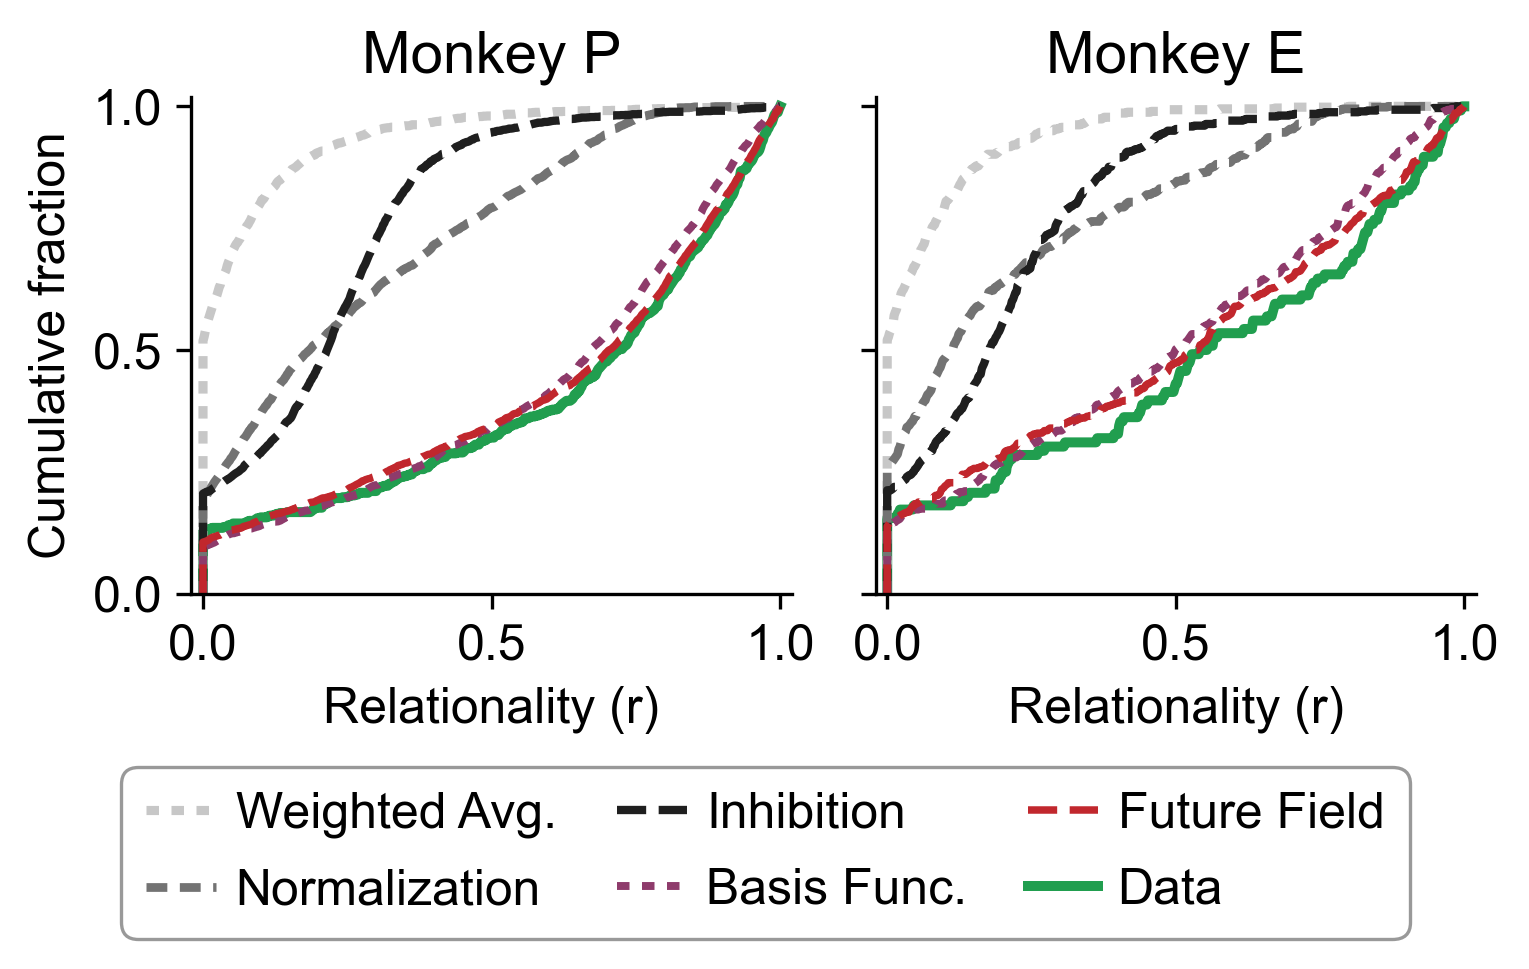

In [3]:
# The metric's own model is the measuring instrument, not one of the models under test, but
# its fitted parameter still has to be in `summary` for `rl.biases` to read — hence the extra
# entry here and nowhere else.
for group, summary in common.selected_fits_good(MODELS + (rl.MODEL,)):
    real = rl.biases(summary, verbose=False)
    print(f'--- {group}: real bias median {real["bias"].median():.3f}, '
          f'{(real["bias"] <= 1e-9).mean():.1%} at 0, '
          f'{(real["bias"] >= 1 - 1e-9).mean():.1%} at 1')

    synth = ks_lib.synthetic_biases(summary, MODELS, CFG, n_reps=N_REPS, seed=SIM_SEED,
                                    n_jobs=N_JOBS)
    print(f'{len(synth)} synthetic neurons')
    display(ks_lib.ks_table(real, synth, MODELS, by_subject=True, n_boot=200).round(3))

    fig, axes = ks_lib.plot_bias_ecdf(
        real, synth, MODELS, colors=COLORS, styles=STYLES,
        data_color=DATA_COLOR,
        figsize=FIGSIZE, wspace=0.14,
        xlabel=XLABEL,
        legend_loc='below', legend_bbox=(0.5, 0.13), legend_margin=0.30, legend_ncol=3,
        legend_columnspacing=1.2, legend_borderpad=0.1, legend_labelspacing=0.6,
        legend_handlelength=1.4, legend_handletextpad=0.4, legend_rounding=0.35,
        legend_edgecolor='0.6', legend_lw=0.8,
        lw_step=0.1,)
    common.save(fig, f'figure_ks_stats_{group}.pdf')
    plt.show()